In [1]:
%matplotlib inline
%load_ext autoreload   
%autoreload 2

import jax
import jax.numpy as jnp
import jax.scipy as jsp
import chex
import numpy as np
from functools import partial
from tqdm import tqdm
import typing as t
import matplotlib.pyplot as plt
import pickle
import os
from IPython.display import clear_output


In [2]:
from flowlenia.optimization.evoflow import EvoFlow, FL_Config
from flowlenia.flowlenia_params import FlowLeniaParams as FlowLenia 

# Experiments

In [3]:
@chex.dataclass
class ExperimentConfig:
    name: str
    task: EvoFlow
    fl_config: FL_Config
    es_config: dict
    seed: jnp.ndarray
    n_seeds: int
    generations: int

# Plots

## Utils

In [4]:
def load_exp_data(dir):
    data = {}
    name = dir.split('/')[-1]
    files = os.listdir(dir)

    with open(f"{dir}/{name}_results.pickle", 'rb') as f:
        data['result'] = pickle.load(f)

    for fil in files:
        if not fil.endswith('.pickle'): continue
        if 'results' in fil or 'config' in fil: continue

        tmp = fil.split('_')
        seed, gen = int(tmp[-2]), int(tmp[-1].replace('gen', '').replace('.pickle', ''))
        data.setdefault(int(seed), {})
        with open(f"{dir}/{fil}", 'rb') as f:
            data[seed][gen] = pickle.load(f)

    return data

In [5]:
def plot_result(datas: dict, ax, downsamp=1, smooth=False, title="", legend=False,
                style_map = None):
    handles = []
    for label, data in datas.items():
        res = data['result']
        x = np.arange(res.shape[1])[::downsamp]
        res_ds = res[:, ::downsamp, :]
        res_ds = np.mean(np.max(res_ds, axis=-1), axis=0)
        if style_map is not None:
             style = style_map[label]
        else :
            style = {'linestyle': '-', 'color': None}
        l = ax.plot(x, res_ds, label=label, **style)
        handles = handles+l
    ax.set_title(title, fontsize='medium', loc='left')
    if legend :
        ax.legend(loc = 'lower right', ncol=2,
           bbox_to_anchor=(0., .99, 1., .102), framealpha=0.,
           fontsize='small')
    return handles

In [6]:
def name_map(exp_name):
    return exp_name

## Load and Plot

In [7]:
%%capture
data_expes = {}
dir = "../../exp_data/metamorph/data"

DM_exp_names = ["metamorph2"]
data_DM = {name_map(exp_name) : load_exp_data(f"{dir}/{exp_name}") for exp_name in DM_exp_names}
data_expes["Metamorphose"] = data_DM

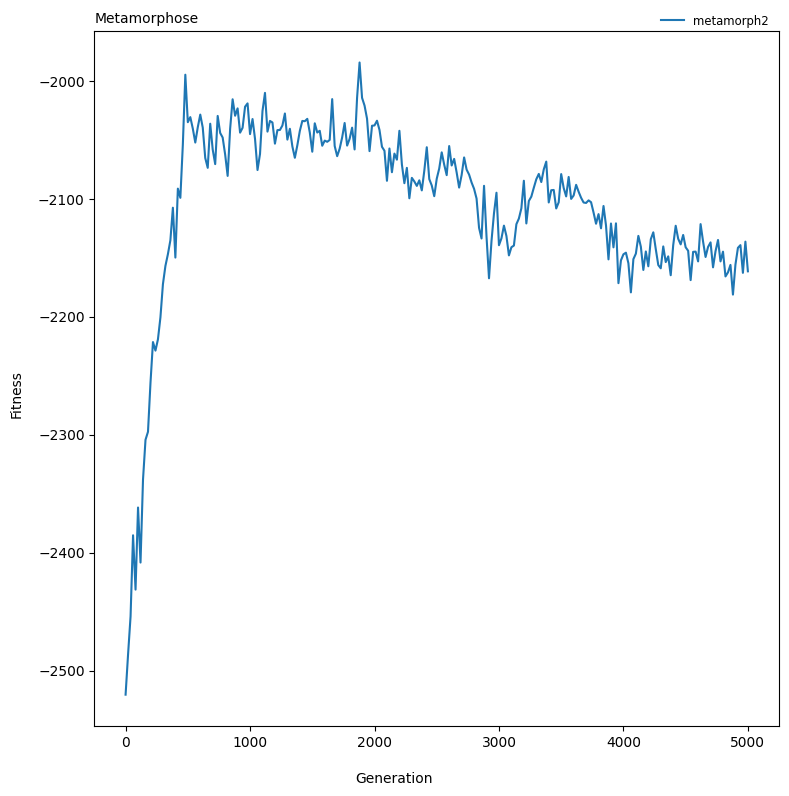

In [8]:
fig, ax = plt.subplots(1, 1, sharex=True, figsize=(8,8))
for i, (exp_name, data) in enumerate(data_expes.items()):
    plot_result(data, ax, downsamp=20, title=exp_name, legend=True)

fig.supxlabel('Generation', fontsize="medium")
fig.supylabel('Fitness', fontsize="medium")
fig.tight_layout()
plt.savefig("metamorph2_evo_results.png", transparent=True, bbox_inches='tight')
plt.show()

In [9]:
fl_config = data_DM["metamorph2"][0][0]['fl_config']
fl = FlowLenia(fl_config, key = jax.random.PRNGKey(0))
X,Y = fl_config.X, fl_config.Y
mx, my = X//2, Y//2
C= fl_config.C

In [10]:
from flowlenia.optimization.evoflow import EvoParams, ParameterReshaper
from flowlenia.optimization.optutils import add_trees,clip_tree, unstack_tree
from flowlenia.utils import sigmoid
from flowlenia.flowlenia_params import State as FL_State


In [11]:
sample_params = fl.rule_space.sample(jax.random.PRNGKey(42))
params_shaper = ParameterReshaper(EvoParams(init = jnp.zeros((40, 40, fl_config.C)), **sample_params))
mu_params = EvoParams(
    init = .5,
    **{k : (inf['low']+inf['high'])/2 for k, inf in fl.rule_space.spaces.items()}
)
lower_params = EvoParams(
    init = 0.,
    **{k : inf['low'] for k, inf in fl.rule_space.spaces.items()}
)
upper_params = EvoParams(
    init = jnp.inf,
    **{k : jnp.inf for k, inf in fl.rule_space.spaces.items()}
)
def process_params(x):
    params = add_trees(params_shaper.reshape(x), mu_params)
    return clip_tree(params, lower_params, upper_params)

ParameterReshaper: 4996 parameters detected for optimization.


In [12]:
steps = 400

In [13]:
def make_video(fl, params, steps, filename, popsize=16, mode = "both"):

    ker_comp_map = jax.vmap(fl.kernel_computer)
    fKs = ker_comp_map(
        params.R,
        params.r,
        params.a,
        params.w,
        params.b,
    )
    As = (
        jnp.zeros((popsize, X, Y, C))
        .at[:, mx - 20 : mx + 20, my - 20 : my + 20, :]
        .set(params.init)
    )
    Ps = jnp.ones((popsize, X, Y, fl_config.k)) * params.h[:, None, None, :]

    init_states = FL_State(A=As, P=Ps, fK=fKs, m=params.m, s=params.s)
    state = unstack_tree(init_states, popsize)[0]
    print(state.A.shape, state.P.shape, state.fK.shape)
    print(state.m.shape, state.s.shape)

    final_state = fl.rollout_and_save_video(
        state, jax.random.PRNGKey(42), steps, filename, fps=30, mode=mode, downscale_factor=0.25
    )

In [14]:
best_params = data_DM["metamorph2"][0][0]["carry"][1].best_member
popsize = 16
best_params = process_params(jnp.array([best_params] * popsize))

make_video(fl, best_params, steps, "metamorph2_0.mp4", popsize=popsize, mode="state")
best_params_end = data_DM["metamorph2"][0][2000]["carry"][1].best_member
best_params_end = process_params(jnp.array([best_params_end] * popsize))
make_video(fl, best_params_end, steps, "metamorph2_5000.mp4", popsize=popsize, mode="state")

(128, 128, 3) (128, 128, 15) (128, 128, 15)
(15,) (15,)


100%|██████████| 400/400 [00:03<00:00, 123.40it/s]

Moviepy - Building video metamorph2_0.mp4.
Moviepy - Writing video metamorph2_0.mp4



100%|██████████| 400/400 [00:04<00:00, 87.18it/s] 


Moviepy - Done !
Moviepy - video ready metamorph2_0.mp4
(128, 128, 3) (128, 128, 15) (128, 128, 15)
(15,) (15,)


100%|██████████| 400/400 [00:02<00:00, 147.41it/s]

Moviepy - Building video metamorph2_5000.mp4.
Moviepy - Writing video metamorph2_5000.mp4



100%|██████████| 400/400 [00:03<00:00, 114.39it/s]

Moviepy - Done !
Moviepy - video ready metamorph2_5000.mp4


In [17]:
from IPython.display import Video
Video("metamorph2_0.mp4", width=800, height=800)

In [18]:
Video("metamorph2_5000.mp4", width=800, height=800)

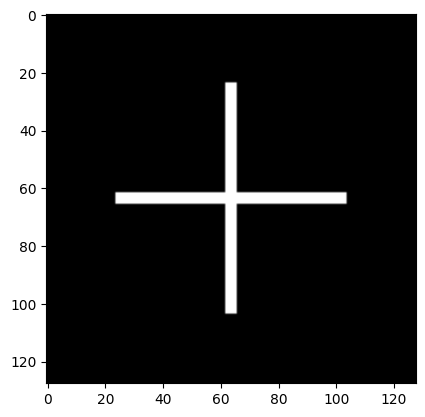

In [82]:
pattern_end = -jnp.ones((X, Y, C))
pattern_end = pattern_end.at[mx - 40 : mx + 40, my - 2 : my + 2, :].set(0)
pattern_end = pattern_end.at[mx - 2 : mx + 2, my - 40 : my + 40, :].set(0)
plt.imshow(pattern_end[:, :, 0], cmap="gray")
plt.imsave("pattern_end.png", pattern_end[:, :, 0], cmap="gray")

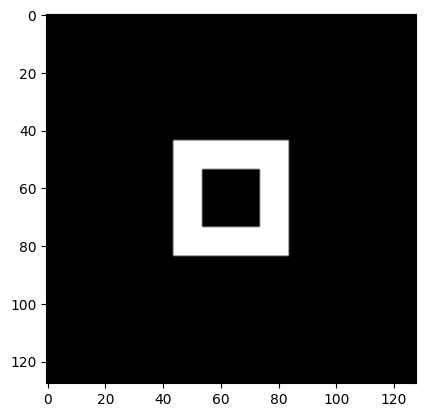

In [4]:
X=128
Y=128
C=3
mx, my = X//2, Y//2
pattern_init = -jnp.ones((X, Y, C))
pattern_init = pattern_init.at[mx - 20 : mx + 20, my - 20 : my + 20, :].set(1)
pattern_init = pattern_init.at[mx - 10 : mx + 10, my - 10 : my + 10, :].set(-1)
plt.imshow(pattern_init[:, :, 0], cmap="gray")
plt.imsave("pattern_init.png", pattern_init[:, :, 0], cmap="gray")

In [81]:
with open(f"../../exp_data/metamorph/data/metamorph1data.pickle", "wb") as handle:
    pickle.dump(data, handle, protocol=pickle.HIGHEST_PROTOCOL)